# Get to Know a Dataset: DE Africa Sentinel-3 LST

This notebook serves as a guided tour of the [Digital Earth Africa Sentinel-3 SLSTR Level-2 LST](https://registry.opendata.aws/[REGISTRY_YAML_NAME]) dataset. More usage examples, tutorials, and documentation for this dataset and others can be found at the [Registry of Open Data on AWS](https://registry.opendata.aws/).



### Dataset Organization & S3 Prefix Structure Overview
***

At the top level of our S3 buckets, we follow a **consistent, product-centric prefix structure** that supports scalable, cloud-native access to **Sentinel-3 SLSTR Level-2 LST products stored as Cloud-Optimised GeoTIFFs (COGs)**.

##### Dataset organisation and key S3 prefix structure
1. **Top-level S3 bucket (per product)**

   The variable is stored in its own dedicated S3 bucket, for example:

   * `s3://deafrica-sentinel-3-slstr-l2-lst/Sentinel-3/SLSTR/SL_2_LST/`

   This separation simplifies data discovery, access management, and scaling as data volumes grow.

2. **Mission prefix**

   ```
   * deafrica-sentinel-3-slstr-l2-lst/
   ```

   Identifies the satellite mission and allows future missions to be added without restructuring existing paths.

3. **Instrument prefix**

   ```
   * SLSTR/
   ```

   Specifies the sensor producing the observations and keeps all products organised consistently.

4. **Processing level and product prefix**

   Each Level-2 product is stored in a dedicated directory, for example:

   * `SL_2_LST` – Sentinel-3 SLSTR Level-2 LST

   This ensures a clear one-to-one mapping between scientific products and directory paths.

5. **Temporal partitioning**

   Products are partitioned by time using:

   ```
   * YYYY/MM/DD/
   ```

   or, where appropriate:

   ```
   * YYYY/MM/
   ```

   Example:

   ```
   * s3://deafrica-sentinel-3-slstr-l2-lst/Sentinel-3/SLSTR/SL_2_LST/
   ```

   Temporal partitioning enables efficient S3 prefix filtering and time-based subsetting in cloud workflows.

6. **Cloud-Optimised GeoTIFFs (COGs)**

   Within each temporal directory are individual **Cloud-Optimised GeoTIFF (`.tif`) files**, where:

   * each file represents a single Sentinel-3 SLSTR Level-2 LST
   * internal tiling and overviews enable HTTP range requests
   * files can be streamed directly into GIS tools, xarray/rioxarray, and Dask without full downloads


Full documentation for this dataset can be found at: [https://docs.digitalearthafrica.org/en/latest/sandbox/notebooks/Datasets/Sentinel_3_Land_Surface_Temperature.html](https://docs.digitalearthafrica.org/en/latest/sandbox/notebooks/Datasets/Sentinel_3_Land_Surface_Temperature.html)




#### Install and import packages

Depending on your environment, you may need to install some packages before importing them. The installation commands in the cell below are effective in Sagemaker Studio Lab (with kernel set to `sagemaker-distribution:Python`) and Google Colab.

If you are running the notebook for the first time, you can remove the `#`s and run the cell below. Often it is more aesthetic to add the `#`s back in after the cell has run because the outputs take a lot of space!

You may see some dependency resolver errors in the output, though this should not affect performance and did not during testing in Colab and SageMaker.

In [1]:
# This notebook requires the following additional libraries
# (Please install using the preferred method for your environment by uncommenting the appropriate lines below):

# !pip install pystac==1.10.0 --force-reinstall
# !pip install odc-stac
# !pip install osmnx
# !pip install pystac_client
# !pip install odc-algo
# !pip install matplotlib
# !pip install -q deafrica-tools
# !pip install -q datacube

In [2]:
# Import the libraries required for this notebook
# Built-ins
import requests
import yaml
import numpy as np
import xarray as xr
import pandas as pd

# Installed libraries
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource
import odc.algo
from pystac_client import Client
from odc.stac import configure_rio, stac_load
from datacube.utils import masking

### Data Formats, Content Types & Practical Usage Guidance

***

Our dataset is stored using **cloud-native geospatial formats**, chosen to support scalable access, analysis, and visualisation directly from S3 without full file downloads.

#### Data formats present in the dataset

##### 1. Cloud-Optimised GeoTIFF (COG) — `.tif`

**What is stored**

* **Sentinel-3 SLSTR Level-2 LST** 
* Each file represents a **single overpass or temporally aggregated product**
* Raster grids with georeferencing, metadata, and quality information

**Why this format is used**

* Internally tiled with overviews
* Supports HTTP range requests
* Optimised for direct cloud access from S3

**How we work with it**

* Stream directly from S3 using `rasterio`, `rioxarray`, or `xarray`
* Subset spatially and temporally without downloading full files
* Visualise instantly in GIS tools (QGIS, ArcGIS)

**Advice**

* Always treat these as *remote datasets*—avoid downloading unless necessary
* Use windowed reads and bounding boxes for performance
* Prefer `rioxarray.open_rasterio()` or STAC-based loading for analysis



##### 2. STAC metadata (JSON)

**What is stored**

* Collection-level and item-level metadata exposed via the **Digital Earth Africa STAC catalogue**
* Spatial extent, temporal coverage, projection, and asset links pointing to the COGs in S3

**Why this format is used**

* Enables structured discovery and filtering of large datasets
* Decouples metadata from physical storage layout

**How we work with it**

* Query using `pystac_client`
* Filter by bounding box, time range, and product type
* Use STAC assets to access COGs programmatically

**Advice**

* Use STAC as the *entry point* rather than hard-coding S3 paths
* Let STAC handle discovery; let raster tools handle reading

This approach keeps workflows **fast, scalable, and cloud-efficient**, even when working with large time series of Sentinel-3 SLSTR Level-2 LST products.

----

### Downloading and Loading Data from the Dataset

We define the location of our dataset, configure access to AWS S3, and prepare the environment for cloud-native data access

We start by configuring Rasterio/GDAL for unsigned (public) S3 access and explicitly point to the Africa (Cape Town) AWS region, where the data are hosted.
This configuration ensures that Cloud-Optimised GeoTIFFs can be accessed efficiently via HTTP range requests without downloading entire files.

In [3]:
configure_rio(
    cloud_defaults=True,
    aws={"aws_unsigned": True},
    AWS_S3_ENDPOINT="s3.af-south-1.amazonaws.com",
)

Next, we open the Digital Earth Africa STAC catalogue, which provides a structured index over the underlying S3 buckets.
We then define:
1. spatial bounding box (in latitude/longitude),
2. temporal window, and
3. the Sentinel-3 SLSTR Level-2 LST collection to query:

In [4]:
# Open the stac catalogue
catalog = Client.open("https://explorer.digitalearth.africa/stac")

# Set a bounding box
# [xmin, ymin, xmax, ymax] in latitude and longitude
bbox =  [35.5, -19.6, 37.3, -17.8]

# Set a start and end date
start_date = '2025-04-01' 
end_date =  '2025-04-15'

To load other Sentinel-3 SLSTR Level-2 LST product, the user only needs to change the value inside the collections list. The product is exposed as a separate STAC collection 

The available options are:
 - `s3_slstr_l2_lst` to work with the product.
   
To load other Sentinel-3 SLSTR Level-2 LST product, use `s3_slstr_l2_lst` in the collections list with the collection corresponding to their variable of interest.

In [5]:
# Set the STAC collections
collections = ["s3_slstr_l2_lst"]

The code block below builds and executes a STAC search query using the parameters you defined earlier, then reports how many matching datasets were found.

First, a query is constructed against the Digital Earth Africa STAC catalogue using:
 - the spatial extent (bbox)
 - the selected Sentinel-3 SLSTR Level-2 LST collection(s) (collections)
 - the time range (start_date to end_date)

In [6]:
query = catalog.search(bbox=bbox, collections=collections, datetime=f"{start_date}/{end_date}")

Next, the query is executed and all matching STAC items (each representing an individual dataset, typically a single overpass or time slice) are retrieved:

In [7]:
# Search the STAC catalog for all items matching the query
items = list(query.items())

Finally, the total number of datasets returned by the search is printed:

In [8]:
print(f"Found: {len(items):d} datasets")

Found: 180 datasets


#### Loads the STAC items into an Xarray Dataset

This step **loads the STAC items into an Xarray Dataset** using cloud-native access, converting the Sentinel-3 SLSTR Level-2 LST STAC assets into an analysis-ready data cube.

Here is what each parameter in `stac_load` is doing:

##### Explanation of key parameters

* **`items`**
  The list of STAC items returned from the catalogue search. Each item corresponds to a  Sentinel-3 SLSTR Level-2 LST observation.

* **`crs="EPSG:4326"`**
  Reprojects the data to geographic coordinates (latitude/longitude), making it easy to work with vector boundaries and other global datasets.

* **`chunks={}`**
  Loads the data lazily (Dask-ready) without forcing a specific chunk size. This is appropriate for small time ranges or exploratory analysis.

* **`groupby="solar_day"`**
  Groups individual overpasses by **solar day**, which is particularly important for Sentinel-3 SLSTR Level-2 LST since multiple orbits can occur within a single day.

* **`bbox=bbox`**
  Spatially subsets the data to the defined area of interest, reducing data volume and improving performance.

* **`resolution=0.01`**
  Sets the output spatial resolution (~1000m at the equator). The negative value ensures correct north-up orientation.

In [9]:
ds_S3 = stac_load(
    items,
    crs='EPSG:4326',
    groupby="solar_day",
    bbox=bbox,
    resolution = -0.01,
)

#### Resulting dataset

The output, `ds_S3`, is an **Xarray Dataset** that:

* contains gridded Sentinel-3 SLSTR Level-2 LST
* is spatially and temporally subsetted
* is ready for time-series analysis, mapping, or aggregation
* streams data directly from Cloud-Optimised GeoTIFFs in S3

Displaying `ds_S3` in the notebook allows you to inspect:

* available variables
* spatial dimensions (`x`, `y`)
* temporal dimension (`time` or `solar_day`)
* metadata and coordinate information

This dataset can now be used for visualisation, statistics, or further cloud-scale processing.

In [10]:
# View the Xarray Dataset
ds_S3

<xarray.Dataset> Size: 6MB
Dimensions:          (latitude: 180, longitude: 180, time: 15)
Coordinates:
  * latitude         (latitude) float64 1kB -19.6 -19.59 ... -17.82 -17.81
  * longitude        (longitude) float64 1kB 37.29 37.28 37.27 ... 35.51 35.5
  * time             (time) datetime64[ns] 120B 2025-04-01 ... 2025-04-15
    spatial_ref      int32 4B 4326
Data variables:
    LST              (time, latitude, longitude) uint16 972kB 65535 ... 29693
    NDVI             (time, latitude, longitude) int16 972kB 32767 ... 32767
    dataMask         (time, latitude, longitude) float32 2MB 0.0 0.0 ... 1.0 1.0
    CONFIDENCE       (time, latitude, longitude) uint16 972kB 514 2 2 ... 8 264
    LST_uncertainty  (time, latitude, longitude) uint16 972kB 65535 65535 ... 54

#### Attach product metadata to the loaded dataset

This cell retrieves the Sentinel-3 SLSTR LST product definition from Digital Earth Africa and adds its metadata to `ds_S3`. Product-level information is stored in the dataset attributes, while measurement-specific information—including units, nodata values and available flag definitions—is attached to each matching variable.

This updates the metadata without reloading the satellite data.

In [11]:
url = ("https://explorer.digitalearth.africa/products/s3_slstr_l2_lst.odc-product.yaml")

response = requests.get(url, timeout=30)
response.raise_for_status()
product = yaml.safe_load(response.text)

# Attach product-level metadata
ds_S3.attrs.update({
    key: value
    for key, value in product.items()
    if key != "measurements"
})

# Attach metadata to every loaded measurement, matching names or aliases
for measurement in product["measurements"]:
    names = [measurement["name"], *measurement.get("aliases", [])]

    for name in names:
        if name in ds_S3.data_vars:
            ds_S3[name].attrs.update(measurement)

#### Applying Scale Factors and Offsets to Sentinel-3 LST Measurements

Some Sentinel-3 SLSTR Land bands are stored as integers with a scale factor (e.g., 0.01) or offset (e.g., 100) applied. This scaling is used to efficiently store values in integer format. To obtain the correct surface values, the scale or offset must be applied. The cells below demonstrate how this is applied to temperature measurements using the scale factor of 0.01 (visible when the metadata is expanded in the dataset above).

As a next step, we store a `scale_factor` object for use in later plots and calculations. The scale factor is extracted from the attributes of the LST variable. We would have to get the specific scale factor for the uncertainty or NDVI variables if we were working with them.

In [12]:
scale_factor_LST = ds_S3['LST'].attrs.get('scale_factor')
scale_factor_LST_unc = ds_S3['LST_uncertainty'].attrs.get('scale_factor')

#### Understanding the Confidence layer and bitmasking

The Sentinel-3 LST data is only available over land (not ocean) and is sensitive to cloud and other interference. In the `xarray` object `ds_S3` above, we can see several 65535 values in the LST variable which represent `nodata`. We need to effectively mask the dataset before proceeding.

The `CONFIDENCE` layer uses a bitmask to encode pixel-level flags, such as cloud presence or sun glint, into a single integer. Bitmask refers to binary digits, where the position of the digit in a series relates to a particular flag. In the `CONFIDENCE` layer, flags are marked true or false with 1s and 0s at specific locations in an integer. Looking at the table below, a 1 at bit location 1 (noting 0 indexing and reading left-to-right, this would be `-1-------...`) would indicate the pixel is over ocean, while a 0 at bit location 3 (`---0-----...`) would indicate the pixel _is not_ over land.

Each active flag contributes a value of $2^{\text{position}}$ to the total integer. For example, if a pixel was over land (position 3, value $2^3=8$), had cosmetic defects (position 8, value $2^8=256$), and was cloudy (position 14, value $2^{14}=16384$), the resulting integer would be:

$$
2^3 + 2^8 + 2^{14} = 16648
$$

Looking at the `CONFIDENCE` band in the `ds_S3` object above, there are a few 16648 values. We have to work backwards from this value to find the unique combination of bit positions with raised flags. Fortunately, computers do this easily and we can draw on the datacube `masking` functions to assist.

The table below shows the bits in the Sentinel-3 LST product.

In [13]:
# Display details of available flags
flags = masking.describe_variable_flags(ds_S3.CONFIDENCE)
flags

,bits,values,description
day,10,"{'0': False, '1': True}",Day
land,3,"{'0': False, '1': True}",Land
snow,13,"{'0': False, '1': True}",Snow
ocean,1,"{'0': False, '1': True}",Ocean
tidal,2,"{'0': False, '1': True}",Tidal
cosmetic,8,"{'0': False, '1': True}",Cosmetic defect
twilight,11,"{'0': False, '1': True}",Twilight
unfilled,5,"{'0': False, '1': True}",Unfilled
coastline,0,"{'0': False, '1': True}",Coastline
duplicate,9,"{'0': False, '1': True}",Duplicate


### Apply the mask

Next, we list the flags we want to mask in a dictionary and apply the `make_mask` function before implementing it on our dataset. In this case, we've chosen three flags: cloud, ocean, unfilled. You can experiement with adding and removing other flags.

In [14]:
clear = {"summary_cloud": False, "ocean": False, "unfilled": False}

mask = masking.make_mask(ds_S3.CONFIDENCE, **clear)

ds_S3_masked = ds_S3.where(mask == True)

## Plot LST and uncertainty in Kelvin

Now that we've applied the mask, we can plot LST and its associated uncertainty, both expressed in Kelvin. Importantly, we apply the scale factor in the plotting commands.

Surface temperatures appear higher along the coasts and in the low lying parts of the Delta, and cooler in the higher topography in the north-west of the area of interest. This is most evident in the 2nd and 14th of April images.

We can also see that the uncertainty values range between 0 and 5 Kelvin. Interestingly, uncertainty appears higher over surface water (the Zambezi River), especially for the 2nd and 5th of April images.

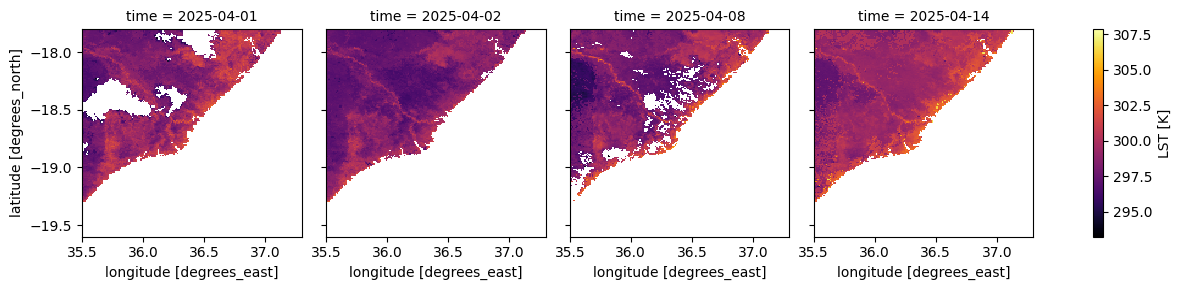

In [15]:
(ds_S3_masked.isel(time=[0,1,7,13]).LST*scale_factor_LST).plot(col='time', cmap = 'inferno')

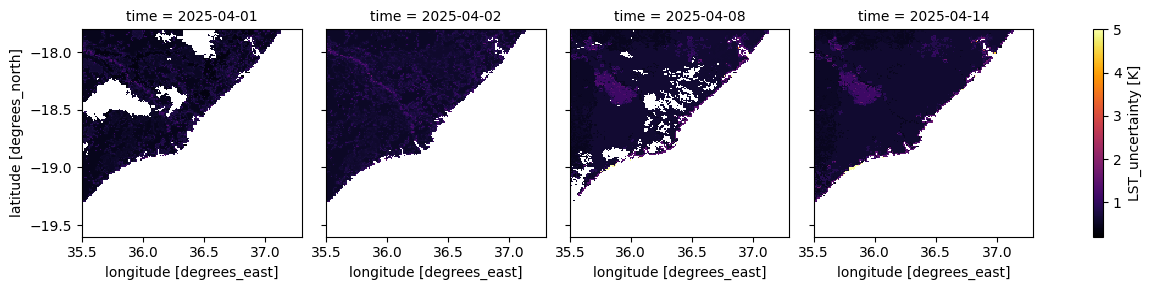

In [16]:
(ds_S3_masked.isel(time=[0,1,7,13]).LST_uncertainty*scale_factor_LST_unc).plot(col='time', cmap = 'inferno')

### Convert LST to Celsius

We can convert Kelvin to Celsius by subtracting 273.15 and plot the result. Using Celsius may be more relatable for some audiences, noting that LST in the area and period plotted ranges between around 20 and 33 degrees Celsius, with cooler temperatures seen in the 5th April image.

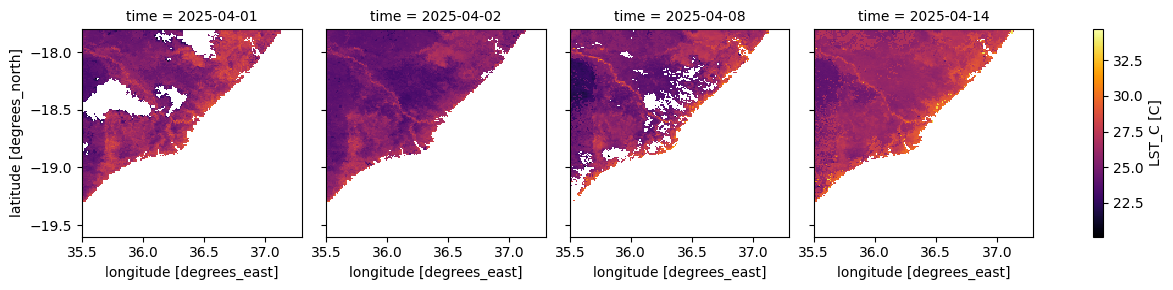

In [17]:
# convert K to C and assign units as an attribute
ds_S3_masked['LST_C'] = (ds_S3_masked.LST*scale_factor_LST - 273.15).assign_attrs(units = "C")

(ds_S3_masked.isel(time=[0,1,7,13]).LST_C).plot(col='time', cmap = 'inferno')

#### What this visual shows

* Each panel represents **LST and CONFIDENCE**, gridded over the area of interest.
* The use of `col="time"` creates a **small-multiples view**, making it easy to compare spatial patterns from day to day.


#### Why this is informative

* You can immediately see **hotspots and gradients** across space.
* Day-to-day differences highlight **temporal variability**, which may be linked to:
* Masked (blank) areas clearly show where **quality filtering** has removed invalid pixels, reinforcing confidence in the data.

#### Why this should excite users

* This is **satellite data streamed directly from the cloud**, not pre-downloaded files.
* With just a few lines of code, users can:

  * visualise total_suspended_matter over any region
  * build time series
* The same workflow scales seamlessly from **two days** to **multiple years** of observations.

#### Takeaway

This visual demonstrates that the dataset is:

* **analysis-ready**
* **spatially rich**
* **temporally dense**
* and perfectly suited for **exploratory science, policy analysis, and storytelling**


### Limitations and next steps

*Are there persistent Temperature in specific regions that recur seasonally, and how do they relate to land use, climate variability, and human activity?*

**Why these data are suitable:**
Sentinel-3 LST provides near-daily, continental-scale coverage, making it possible to detect recurring spatial patterns and seasonal signals that are difficult to observe with sparse ground measurements.

**Recommendations for answering this question:**

* Analyse **multi-year time series** rather than short windows to separate seasonal cycles from noise.
* Apply **strict quality and cloud filtering** before any aggregation.
* Use **consistent spatial grids and temporal grouping** (e.g. solar day or monthly composites).
* Validate patterns where possible using inventories or independent observations.

This approach allows users to move from short-term exploration to **robust, policy-relevant insights**.